# Plotting timelapse

For plotting a timelapse, we use a convenience function named `generate_plot_stack` in [dwd_weather.py](dwd_weather.py). We basically only need to pre-filter the dataframe for the time frame that should be plotted. 

In [1]:
import pandas as pd
import numpy as np
import stackview
from datetime import datetime, timedelta
import numpy as np
from dwd_weather import load_borders, generate_plot_stack

In [2]:
rain_dataset = "rain_recent"
temp_dataset = "temp_recent"

selected_time_point = datetime(2026, 6, 30, 00, 00)
num_days = 4 # backwards

In [3]:
df = pd.read_parquet(temp_dataset + ".parquet")
df.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor,Stations_id,von_datum,bis_datum,Stationshoehe,geoBreite,geoLaenge,Stationsname,Bundesland,Abgabe,datetime
0,44,202412310000,3,-999.0,6.4,6.0,87.3,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:00:00
1,44,202412310010,3,-999.0,6.4,6.1,86.9,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:10:00
2,44,202412310020,3,-999.0,6.4,5.9,87.5,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:20:00
3,44,202412310030,3,-999.0,6.4,6.0,87.1,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:30:00
4,44,202412310040,3,-999.0,6.4,5.9,87.9,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:40:00


In [4]:
timepoint = df[df["datetime"] < selected_time_point]
timepoint = timepoint[timepoint["datetime"] > selected_time_point - timedelta(days=num_days)]
timepoint.shape

(268525, 19)

100%|██████████| 96/96 [00:16<00:00,  5.68it/s]


(96, 600, 500, 3)


C:\Users\haase\miniforge3\envs\bob-env\Lib\site-packages\stackview\_animate.py:63: UserWarning: The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.
  warnings.warn("The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.")



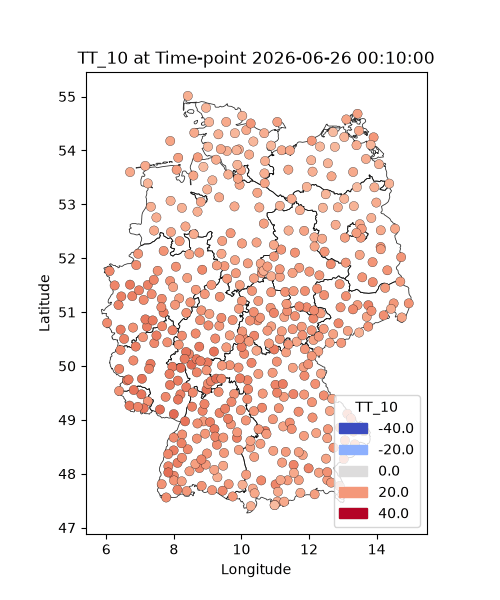

In [5]:
stack = generate_plot_stack(
    timepoint,
    "TT_10",
    min_value=-40,
    max_value=40,
    colormap="coolwarm",
    borders_gdf=load_borders(),
    step=6 # one plot per hour
)
print(stack.shape)
stackview.animate(stack, "temperature.gif")

When executing this notebook locally, you can also navigate through this data manually:

In [6]:
stackview.slice(stack)

In [7]:
df2 = pd.read_parquet(rain_dataset + ".parquet")
timepoint2 = df2[df2["datetime"] < selected_time_point]
timepoint2 = timepoint2[timepoint2["datetime"] > selected_time_point - timedelta(days=num_days)]
timepoint2.shape

(266800, 17)

100%|██████████| 96/96 [00:16<00:00,  5.76it/s]


(96, 600, 500, 3)


C:\Users\haase\miniforge3\envs\bob-env\Lib\site-packages\stackview\_animate.py:63: UserWarning: The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.
  warnings.warn("The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.")



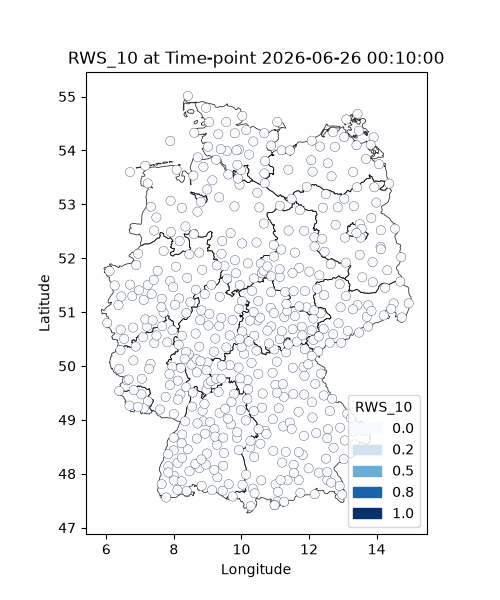

In [8]:
stack2 = generate_plot_stack(
    timepoint2,
    "RWS_10",
    min_value=0,
    max_value=1,
    colormap="Blues",
    borders_gdf=load_borders(),
    step=6 # one plot per hour
)
print(stack.shape)
stackview.animate(stack2, "rain.gif")

In [9]:
stackview.slice(stack2)

Finally, we store a side-by-side view of both plots as teaser for the website.

In [10]:
combined = np.concatenate([stack, stack2], axis=2)
combined.shape

(96, 600, 1000, 3)

In [13]:
stackview.animate(combined, filename="video.gif", frame_delay_ms=50);

C:\Users\haase\miniforge3\envs\bob-env\Lib\site-packages\stackview\_animate.py:63: UserWarning: The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.
  warnings.warn("The image is quite large (> 10 MByte) and might not be properly shown in the notebook when rendered over the internet. Consider subsampling or cropping the image for visualization purposes.")


In [14]:
stackview.slice(combined)